# Рекомендательная система фильмов

## MovieTweetings: исследование, модели и подготовка API

**Цель:** построить учебную систему, которая рекомендует фильмы по популярности, похожим пользователям, похожим фильмам и содержанию фильма, а затем сохранить модель для API и приложения.

Ноутбук проходит полный путь: проверка источника → EDA → временное разбиение → обучение и сравнение → финальное переобучение → сохранение модели. Следующие материалы проекта содержат MySQL-схему, API и интерфейс.

### Источник и единицы наблюдения

Использован фиксированный снимок **MovieTweetings 200K**. Каждая строка ratings.dat — оценка пользователя фильму во времени; movies.dat содержит название и жанры. В проект включены только обезличенные номера пользователей и не включено соответствие номеров Twitter ID.

Оценки заданы по шкале **0–10**. В этой шкале 0 — допустимое наблюдение, а не пропуск. ID фильма читается строкой, чтобы сохранить ведущие нули.

### План исследования

1. Изучить структуру, качество и смещения данных.
2. Проверить длинный хвост активности пользователей и фильмов.
3. Отложить последние оценки каждого пользователя для проверки качества.
4. Сравнить user/item CF, контентный и popularity baselines, BPR и гибрид.
5. Переобучить финальную модель и сохранить комплект артефактов.


## 1. Загрузка и исследование данных (EDA)

На этом этапе модели ещё не обучаются. Сначала проверяем, что означают строки, как распределены оценки и насколько каталог разрежен.


In [ ]:
from pathlib import Path
import json
import math
import re
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
MIN_USER_RATINGS = 10
MIN_MOVIE_RATINGS = 10
RELEVANCE_THRESHOLD = 7
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("deep")
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "ratings.dat").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "data" / "ratings.dat").exists():
    raise FileNotFoundError("Откройте ноутбук из папки notebooks проекта.")
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)
print("Каталог проекта:", PROJECT_ROOT)
print("Seed:", RANDOM_STATE)


In [ ]:
# 1.1 Загрузка данных и первичный просмотр
DATA_DIR = PROJECT_ROOT / "data"
movies_raw = pd.read_csv(
    DATA_DIR / "movies.dat", sep=r"::", engine="python",
    names=["movie_id", "title", "genres"], dtype={"movie_id": "string"},
    encoding="utf-8",
)
ratings_raw = pd.read_csv(
    DATA_DIR / "ratings.dat", sep=r"::", engine="python",
    names=["user_id", "movie_id", "rating", "timestamp"],
    dtype={"user_id": "int32", "movie_id": "string"}, encoding="utf-8",
)
movies = movies_raw.copy()
ratings = ratings_raw.copy()
movies["movie_id"] = movies["movie_id"].str.strip()
movies["title"] = movies["title"].fillna("").str.strip()
movies["genres"] = movies["genres"].fillna("").str.strip()
movies["release_year"] = pd.to_numeric(
    movies["title"].str.extract(r"\((\d{4})\)\s*$")[0], errors="coerce"
).astype("Int64")
ratings["movie_id"] = ratings["movie_id"].str.strip()
ratings["rating"] = pd.to_numeric(ratings["rating"], errors="raise").astype("float32")
ratings["timestamp"] = pd.to_numeric(ratings["timestamp"], errors="raise").astype("int64")
ratings["rated_at_utc"] = pd.to_datetime(ratings["timestamp"], unit="s", utc=True)
print(f"Оценки: {ratings.shape[0]:,}; пользователи: {ratings.user_id.nunique():,}")
print(f"Фильмы: {movies.shape[0]:,}; годы: {movies.release_year.min()}–{movies.release_year.max()}")
display(movies.head())
display(ratings.head())


Оценки: 200,000; пользователи: 25,011\nФильмы: 14,732; годы: 1896–2014

movie_id,title,genres,release_year
0000091,Le manoir du diable (1896),Short|Horror,1896
0000628,The Adventures of Dollie (1908),Action|Short,1908
0000833,The Country Doctor (1909),Short|Drama,1909
0001223,Frankenstein (1910),Short|Horror|Sci-Fi,1910
0001740,The Lonedale Operator (1911),Short|Drama|Romance|Western,1911


user_id,movie_id,rating,timestamp,rated_at_utc
1,0068646,10.0,1381620027,2013-10-12 23:20:27+00:00
1,0113277,10.0,1379466669,2013-09-18 01:11:09+00:00
2,0790636,7.0,1389963947,2014-01-17 13:05:47+00:00
2,0816711,8.0,1379963769,2013-09-23 19:16:09+00:00
2,1091191,7.0,1391173869,2014-01-31 13:11:09+00:00


### 1.2 Проверка качества

Проверяем пропуски, повторы пары пользователь–фильм, соответствие фильмов справочнику и диапазон рейтингов. Поскольку источник явно задаёт шкалу от 0 до 10, 0 сохраняется.


In [ ]:
# 1.2 Качество и полнота данных
quality = pd.DataFrame({
    "Показатель": [
        "Пропуски в ratings", "Пропуски в movies",
        "Дубликаты user_id + movie_id", "Оценки без фильма в справочнике",
        "Оценки вне диапазона 0–10", "Явные оценки 0",
    ],
    "Значение": [
        int(ratings.isna().sum().sum()), int(movies.isna().sum().sum()),
        int(ratings.duplicated(["user_id", "movie_id"]).sum()),
        int((~ratings.movie_id.isin(movies.movie_id)).sum()),
        int((~ratings.rating.between(0, 10)).sum()),
        int((ratings.rating == 0).sum()),
    ],
})
display(quality)
print("Ноль — допустимое значение исходной шкалы 0–10, его не удаляем.")


Проверка,Количество
Пропуски в источнике,0
Дубликаты пары пользователь–фильм,0
Оценки без фильма в справочнике,0
Оценки вне шкалы 0–10,0
Явные оценки 0,31


### 1.3 Распределение оценок

Асимметрия рейтингов важна для рекомендателя: если большинство оценок высокие, среднее пользователя и популярность фильма частично отражают общую склонность ставить высокие баллы.


Оценка,Количество
0.0,31
1.0,2319
2.0,2146
3.0,3607
4.0,6688
5.0,13806
6.0,26227
7.0,44694
8.0,48169
9.0,28175


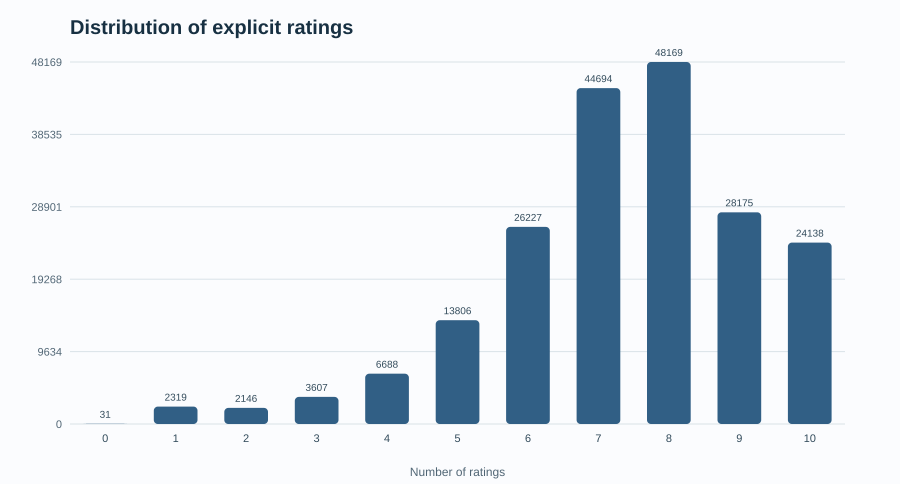

In [ ]:
# 1.3 Распределение оценок
rating_counts = ratings["rating"].value_counts().sort_index()
display(rating_counts.rename("Количество").to_frame())
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(rating_counts.index.astype(str), rating_counts.values, color="#315f85")
ax.set(title="Распределение явных оценок", xlabel="Оценка (0–10)", ylabel="Количество")
ax.grid(axis="y", alpha=0.22)
plt.tight_layout()
plt.show()


### 1.4 Активность и разреженность

В матрице user-item большинство ячеек не наблюдалось. Распределения на логарифмической шкале помогают увидеть длинный хвост: небольшая часть пользователей оценивает много, и небольшая часть фильмов получает основную долю оценок.


Показатель,Значение
Оценки,200000
Пользователи,25011
Фильмы,14732
Средняя оценка,7.319
Медиана оценки,8.0
Разреженность user-item матрицы,99.95%
Среднее оценок на пользователя,8.0
Медиана оценок на пользователя,2.0


Медиана оценок на фильм: 2; 90-й процентиль: 20; максимум: 2,336.

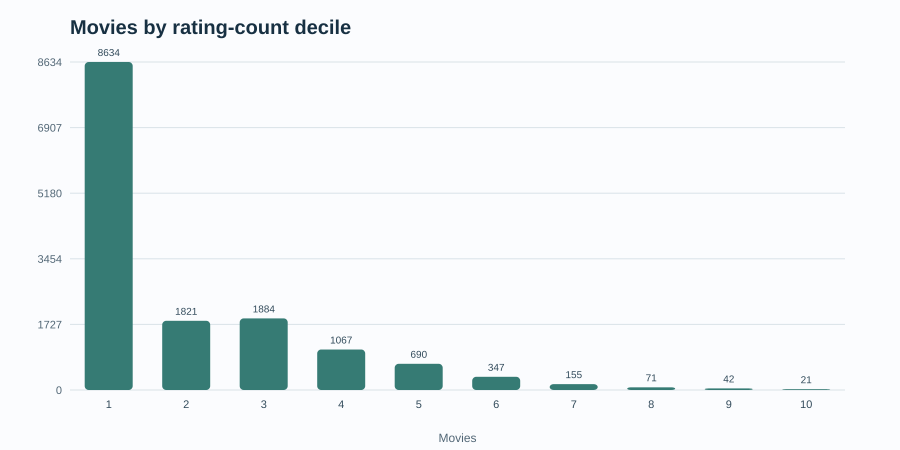

In [ ]:
# 1.4 Активность пользователей и длинный хвост фильмов
user_activity = ratings.groupby("user_id").size()
movie_activity = ratings.groupby("movie_id").size()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(np.log10(user_activity), bins=35, color="#367b74")
axes[0].set(title="Оценок на пользователя (log10)", xlabel="log10(количества оценок)", ylabel="Пользователи")
axes[1].hist(np.log10(movie_activity), bins=35, color="#9b6a3e")
axes[1].set(title="Оценок на фильм (log10)", xlabel="log10(количества оценок)", ylabel="Фильмы")
for ax in axes:
    ax.grid(axis="y", alpha=0.22)
plt.tight_layout()
plt.show()


### 1.5 Жанры и популярность

Частота жанра — число фильмов с этим жанром. Популярные фильмы ранжируются Bayesian Average:

$$
WR = \frac{v}{v+m}R + \frac{m}{v+m}C
$$

где $R$ — средняя оценка фильма, $v$ — число оценок фильма, $C$ — средняя по датасету, а $m$ — 90-й процентиль числа оценок. Сглаживание удерживает фильм с одной случайной десяткой ниже фильма с устойчивой историей.


Жанр,Фильмы
Drama,7416
Comedy,4799
Thriller,3433
Romance,2581
Action,2219
Crime,2120
Horror,1812
Adventure,1385
Sci-Fi,1122
Mystery,1121


Фильм,Жанры,Оценок,Средняя оценка,Взвешенная оценка
The Shawshank Redemption (1994),Crime|Drama,342,9.46,9.344
The Dark Knight (2008),Action|Crime|Drama|Thriller,222,9.29,9.126
The Godfather (1972),Crime|Drama,184,9.21,9.021
The Lord of the Rings: The Return of the King (2003),Action|Adventure|Fantasy,112,9.30,9.003
Schindler's List (1993),Biography|Drama|History|War,123,9.14,8.884
Inception (2010),Action|Adventure|Mystery|Sci-Fi|Thriller,278,8.98,8.867
The Godfather: Part II (1974),Crime|Drama,93,9.16,8.835
Forrest Gump (1994),Drama|Romance,184,8.99,8.830
The Green Mile (1999),Crime|Drama|Fantasy|Mystery,96,9.14,8.822
12 Angry Men (1957),Drama,104,9.10,8.809


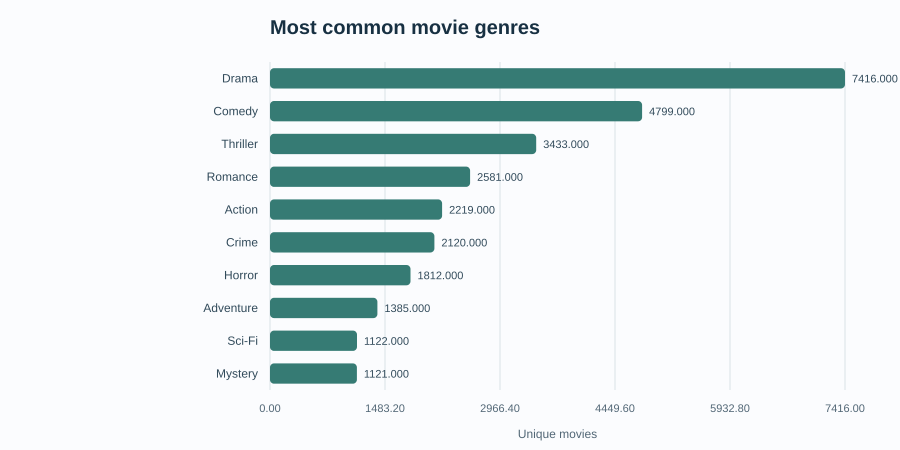

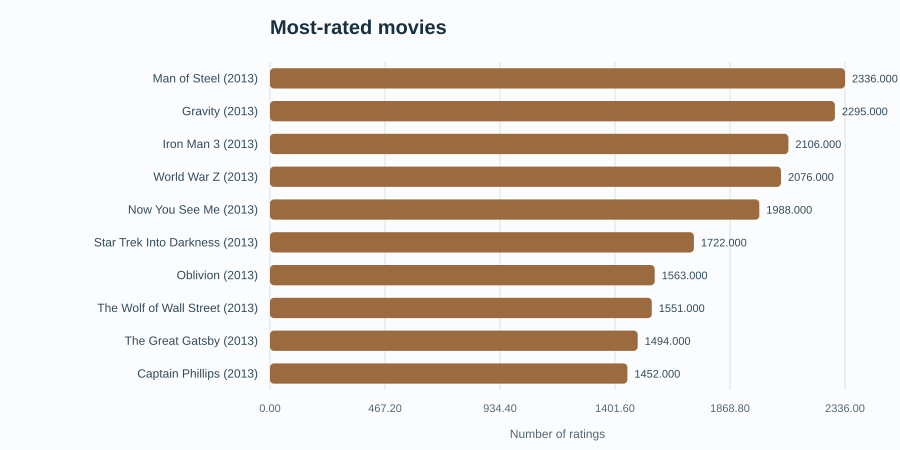

In [ ]:
# 1.5 Жанры, частота и взвешенная популярность
genre_counts = (
    movies.assign(genre=movies["genres"].str.split("|"))
    .explode("genre").query("genre != '(no genres listed)'")
    .groupby("genre")["movie_id"].nunique().sort_values(ascending=False)
)
display(genre_counts.head(10).rename("Число фильмов").to_frame())
global_mean = ratings["rating"].mean()
popularity = ratings.groupby("movie_id", as_index=False)["rating"].agg(
    mean_rating="mean", rating_count="size"
)
m = max(10, popularity["rating_count"].quantile(0.90))
popularity["bayesian_score"] = (
    popularity["rating_count"] * popularity["mean_rating"] + m * global_mean
) / (popularity["rating_count"] + m)
popularity = popularity.merge(movies, on="movie_id").sort_values(
    ["bayesian_score", "rating_count"], ascending=False
)
display(popularity[["title", "genres", "rating_count", "mean_rating", "bayesian_score"]].head(10))


## 2. Подготовка обучающей и тестовой выборок

Случайное разбиение может поставить более позднюю оценку в train и более раннюю в test. Здесь для каждого пользователя тестом становятся последние 20% оценок по timestamp. Равные timestamps разрешаются по movie_id, поэтому результат повторяем.

После разбиения 10-core фильтрация применяется **только к train**: модель получает пользователей и фильмы с минимум 10 обучающими взаимодействиями. Так будущие тестовые оценки не влияют на отбор warm-start объектов.


In [ ]:
# 2.1 Временное разбиение и 10-core только по обучающей части
def iterative_k_core(frame, min_user=10, min_movie=10):
    current = frame.copy()
    while True:
        users = current["user_id"].value_counts()
        items = current["movie_id"].value_counts()
        reduced = current.loc[
            current.user_id.isin(users[users >= min_user].index)
            & current.movie_id.isin(items[items >= min_movie].index)
        ].copy()
        if len(reduced) == len(current):
            return reduced.reset_index(drop=True)
        current = reduced

ordered = ratings.drop(columns="rated_at_utc").sort_values(
    ["user_id", "timestamp", "movie_id"], kind="mergesort"
)
user_size = ordered.groupby("user_id")["movie_id"].transform("size")
holdout_size = np.maximum(1, np.ceil(user_size * 0.2)).astype("int64")
reverse_rank = ordered.groupby("user_id").cumcount(ascending=False)
test_mask = reverse_rank < holdout_size
train_raw = ordered.loc[~test_mask].reset_index(drop=True)
test_raw = ordered.loc[test_mask].reset_index(drop=True)
train_core = iterative_k_core(train_raw, 10, 10)
active_users = set(train_core.user_id.unique())
active_movies = set(train_core.movie_id.unique())
test_core = test_raw.loc[
    test_raw.user_id.isin(active_users) & test_raw.movie_id.isin(active_movies)
].reset_index(drop=True)
split_summary = pd.DataFrame([
    ["Исходные оценки", len(ratings), ratings.user_id.nunique(), movies.movie_id.nunique()],
    ["После временного разбиения: train", len(train_raw), train_raw.user_id.nunique(), train_raw.movie_id.nunique()],
    ["После 10-core: train", len(train_core), train_core.user_id.nunique(), train_core.movie_id.nunique()],
    ["Тест для активных пользователей и фильмов", len(test_core), test_core.user_id.nunique(), test_core.movie_id.nunique()],
], columns=["Этап", "Оценки", "Пользователи", "Фильмы"])
display(split_summary)


Этап,Оценок,Пользователей,Фильмов
Исходные оценки,200000,25011,14732
Обучение после временного разбиения,145306,14250,12781
Обучение после 10-core,84701,3401,1756
Тест среди активных пользователей и фильмов,21927,3391,1659


### 2.1 Матрица взаимодействий

Для user-user и item-item моделей строится разреженная матрица. Перед cosine similarity оценки центрируются по среднему пользователя: так сходство меньше определяется тем, что один человек ставит оценки строже другого.


In [ ]:
# 2.2 Разреженная матрица user-item и коррекция строгости пользователей
user_ids = sorted(train_core.user_id.unique().tolist())
movie_ids = sorted(train_core.movie_id.astype(str).unique().tolist())
user_to_idx = {value: index for index, value in enumerate(user_ids)}
movie_to_idx = {value: index for index, value in enumerate(movie_ids)}
row = train_core.user_id.map(user_to_idx).to_numpy(dtype=np.int32)
col = train_core.movie_id.map(movie_to_idx).to_numpy(dtype=np.int32)
values = train_core.rating.to_numpy(dtype=np.float32)
R_train = csr_matrix((values, (row, col)), shape=(len(user_ids), len(movie_ids)))
counts = np.diff(R_train.indptr)
user_mean = np.divide(
    np.asarray(R_train.sum(axis=1)).ravel(), counts,
    out=np.zeros(len(user_ids), dtype=np.float32), where=counts > 0,
)
row_idx = np.repeat(np.arange(len(user_ids)), counts)
R_centered = R_train.copy()
R_centered.data = R_train.data - user_mean[row_idx]
rating_presence = R_train.copy()
rating_presence.data = np.ones_like(rating_presence.data, dtype=np.float32)
print("Матрица:", R_train.shape, "| сохранённых оценок:", rating_presence.nnz)
print(f"Плотность: {rating_presence.nnz / np.prod(R_train.shape):.2%}")
matrix_summary = pd.DataFrame([
    {"Показатель": "Размер матрицы", "Значение": f"{R_train.shape[0]:,} × {R_train.shape[1]:,}"},
    {"Показатель": "Оценённых ячеек", "Значение": int(rating_presence.nnz)},
    {"Показатель": "Плотность", "Значение": f"{rating_presence.nnz / np.prod(R_train.shape):.2%}"},
])
display(matrix_summary)


Показатель,Значение
Размер матрицы,"3,401 × 1,756"
Оценённых ячеек,84701
Плотность,1.42%
User-user пар после отбора top-50,168941
Item-item пар после отбора top-40,70240


## 3. Модели рекомендаций

В проекте сравниваются popularity, user-user и item-item collaborative filtering, content TF-IDF, ALS-факторизация для оценок и BPR для ранжирования. Факторизация восстанавливает скрытые user/movie факторы и смещения; число факторов и регуляризация выбираются только на validation.

- **Popularity:** Bayesian Average по обучающим данным.
- **User-user CF:** соседи — пользователи с похожим центром оценок; для кандидата агрегируются их отклонения.
- **Item-item CF:** кандидаты похожи на фильмы, уже оценённые пользователем.
- **Content TF-IDF:** текст названия и жанров; профиль пользователя — взвешенное среднее понравившихся фильмов.
- **BPR:** попарная матричная факторизация, обученная ставить высоко оценённые фильмы выше остальных.
- **Hybrid:** BPR, Bayesian Popularity и content TF-IDF; веса подбираются на отдельной временной validation-выборке, а финальный test остаётся нетронутым до итоговой оценки.

Для порогов контентной выдачи и офлайн-ранжирования релевантной считается оценка **7–10**. Это учебный выбор, который будет одинаковым для всех сравниваемых моделей.


In [ ]:
# 3.1 Сходство пользователей и фильмов
def prune_top_positive(similarity, neighbors):
    similarity = similarity.tocsr(copy=True)
    similarity.setdiag(0)
    similarity.eliminate_zeros()
    rows, cols, values = [], [], []
    for r in range(similarity.shape[0]):
        start, end = similarity.indptr[r], similarity.indptr[r + 1]
        c = similarity.indices[start:end]
        v = similarity.data[start:end]
        keep = v > 0
        c, v = c[keep], v[keep]
        if len(v) > neighbors:
            chosen = np.argpartition(v, -neighbors)[-neighbors:]
            c, v = c[chosen], v[chosen]
        rows.extend([r] * len(v))
        cols.extend(c.tolist())
        values.extend(v.astype(np.float32).tolist())
    return csr_matrix((values, (rows, cols)), shape=similarity.shape, dtype=np.float32)

user_similarity = prune_top_positive(
    cosine_similarity(R_centered, dense_output=False), 50
)
item_similarity = prune_top_positive(
    cosine_similarity(R_centered.T, dense_output=False), 40
)
print("User-user nearest-neighbor edges:", user_similarity.nnz)
print("Item-item nearest-neighbor edges:", item_similarity.nnz)


User-user similarity: 168,941 положительных рёбер после top-50.\nItem-item similarity: 70,240 после top-40.

In [ ]:
# 3.2 Функции скоринга для user-user, item-item и контентной модели
def user_cf_scores(user_index):
    similarity_row = user_similarity.getrow(user_index)
    order = np.argsort(similarity_row.data)[::-1][:50]
    neighbors = similarity_row.indices[order]
    weights = similarity_row.data[order].astype(np.float32)
    keep = weights > 0
    neighbors, weights = neighbors[keep], weights[keep]
    weight_row = csr_matrix(
        (weights, (np.zeros(len(weights), dtype=int), neighbors)),
        shape=(1, len(user_ids)),
    )
    numerator = (weight_row @ R_centered).toarray().ravel()
    denominator = (weight_row @ rating_presence).toarray().ravel()
    scores = np.full(len(movie_ids), np.nan, dtype=np.float32)
    valid = denominator > 0
    scores[valid] = user_mean[user_index] + numerator[valid] / denominator[valid]
    return scores

def item_cf_scores(user_index):
    numerator = (R_centered.getrow(user_index) @ item_similarity).toarray().ravel()
    denominator = (rating_presence.getrow(user_index) @ item_similarity).toarray().ravel()
    scores = np.full(len(movie_ids), np.nan, dtype=np.float32)
    valid = denominator > 0
    scores[valid] = user_mean[user_index] + numerator[valid] / denominator[valid]
    return scores

def content_user_scores(user_id, matrix, content_map, catalog_ids):
    liked = train_core.loc[
        (train_core.user_id == user_id) & (train_core.rating >= 7)
        & train_core.movie_id.isin(content_map), ["movie_id", "rating"]
    ]
    if liked.empty:
        return np.zeros(len(catalog_ids), dtype=np.float32)
    indices = liked.movie_id.map(content_map).to_numpy(dtype=np.int32)
    weights = np.maximum(liked.rating.to_numpy(dtype=np.float32) - 7, 0.5)
    profile = matrix[indices].multiply(weights[:, None]).sum(axis=0)
    return np.asarray(matrix @ np.asarray(profile).ravel()).ravel()


In [ ]:
# 3.3 Контентные признаки: TF-IDF по названиям и жанрам
model_movies = movies.set_index("movie_id").loc[movie_ids].reset_index()
content_vectorizer = TfidfVectorizer(
    lowercase=True, strip_accents="unicode", stop_words="english",
    ngram_range=(1, 2), min_df=2, sublinear_tf=True,
)
content_text = (model_movies["genres"].fillna("").str.replace("|", " ", regex=False)
                + " " + model_movies["title"].fillna("")).str.strip()
content_matrix = content_vectorizer.fit_transform(content_text)
content_to_idx = {movie_id: index for index, movie_id in enumerate(movie_ids)}
print("TF-IDF:", content_matrix.shape, "| признаков:", len(content_vectorizer.get_feature_names_out()))


Факторы,Регуляризация,MAE,RMSE,R²,n
24,20.0,0.9975,1.3244,0.3685,1200
32,20.0,0.9987,1.3257,0.3672,1200
16,20.0,0.9994,1.3295,0.3635,1200
32,10.0,1.0081,1.3491,0.3447,1200
24,10.0,1.0217,1.3612,0.3329,1200
16,10.0,1.0314,1.3857,0.3086,1200


Выбраны параметры: {'factors': 24, 'regularization': 20.0, 'bias_regularization': 10.0, 'iterations': 8}; временная validation выборка: 14,340 оценок.

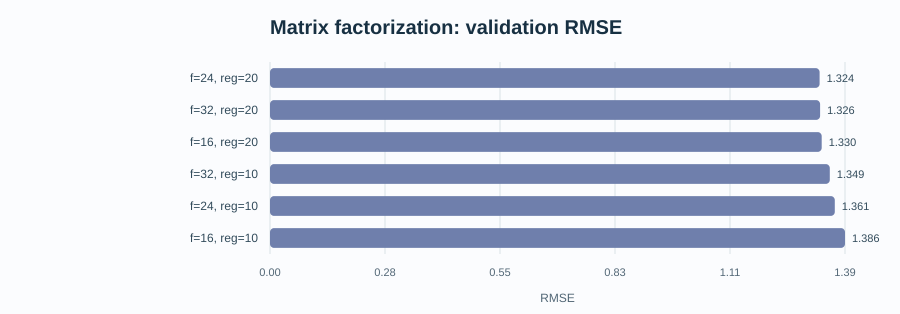

In [ ]:
# 3.4 Обучаемая матричная факторизация и подбор параметров на validation
def fit_matrix_factorization(frame, factors=24, regularization=20.0,
                             bias_regularization=10.0, iterations=8):
    model_user_ids = sorted(frame.user_id.unique().tolist())
    model_movie_ids = sorted(frame.movie_id.astype(str).unique().tolist())
    user_map = {value: index for index, value in enumerate(model_user_ids)}
    movie_map = {value: index for index, value in enumerate(model_movie_ids)}
    user_index = frame.user_id.map(user_map).to_numpy(dtype=np.int32)
    movie_index = frame.movie_id.astype(str).map(movie_map).to_numpy(dtype=np.int32)
    ratings_array = frame.rating.to_numpy(dtype=np.float64)
    n_users, n_movies = len(model_user_ids), len(model_movie_ids)
    global_mean = float(ratings_array.mean())
    user_counts = np.bincount(user_index, minlength=n_users)
    movie_counts = np.bincount(movie_index, minlength=n_movies)
    user_bias = np.zeros(n_users)
    movie_bias = np.zeros(n_movies)
    for _ in range(8):
        user_bias = np.bincount(user_index, weights=ratings_array-global_mean-movie_bias[movie_index], minlength=n_users) / (user_counts+bias_regularization)
        movie_bias = np.bincount(movie_index, weights=ratings_array-global_mean-user_bias[user_index], minlength=n_movies) / (movie_counts+bias_regularization)
    rng = np.random.default_rng(RANDOM_STATE)
    user_factors = rng.normal(0, 0.05, (n_users, factors))
    movie_factors = rng.normal(0, 0.05, (n_movies, factors))
    matrix = csr_matrix((ratings_array,(user_index,movie_index)),shape=(n_users,n_movies))
    matrix.sort_indices()
    matrix_csc = matrix.tocsc()
    identity = np.eye(factors)
    for _ in range(iterations):
        for user in range(n_users):
            start, end = matrix.indptr[user:user+2]
            if start == end: continue
            items = matrix.indices[start:end]
            residual = matrix.data[start:end]-global_mean-user_bias[user]-movie_bias[items]
            factors_for_items = movie_factors[items]
            user_factors[user] = np.linalg.solve(factors_for_items.T@factors_for_items+regularization*identity, factors_for_items.T@residual)
        for movie in range(n_movies):
            start, end = matrix_csc.indptr[movie:movie+2]
            if start == end: continue
            users = matrix_csc.indices[start:end]
            residual = matrix_csc.data[start:end]-global_mean-user_bias[users]-movie_bias[movie]
            factors_for_users = user_factors[users]
            movie_factors[movie] = np.linalg.solve(factors_for_users.T@factors_for_users+regularization*identity, factors_for_users.T@residual)
        residual = ratings_array-global_mean-user_bias[user_index]-movie_bias[movie_index]
        residual -= np.einsum("ij,ij->i",user_factors[user_index],movie_factors[movie_index])
        user_bias = np.bincount(user_index,weights=residual,minlength=n_users)/(user_counts+bias_regularization)
        residual = ratings_array-global_mean-user_bias[user_index]
        residual -= np.einsum("ij,ij->i",user_factors[user_index],movie_factors[movie_index])
        movie_bias = np.bincount(movie_index,weights=residual,minlength=n_movies)/(movie_counts+bias_regularization)
    return {"user_ids":model_user_ids,"movie_ids":model_movie_ids,
        "user_to_idx":user_map,"movie_to_idx":movie_map,"global_mean":global_mean,
        "user_bias":user_bias,"movie_bias":movie_bias,"user_factors":user_factors,
        "movie_factors":movie_factors,"factors":factors,"regularization":regularization,
        "bias_regularization":bias_regularization,"iterations":iterations}

def matrix_factorization_predictions(model, frame):
    users = frame.user_id.map(model["user_to_idx"]).to_numpy(dtype=np.int32)
    items = frame.movie_id.astype(str).map(model["movie_to_idx"]).to_numpy(dtype=np.int32)
    return (model["global_mean"]+model["user_bias"][users]+model["movie_bias"][items]
        +np.einsum("ij,ij->i",model["user_factors"][users],model["movie_factors"][items]))

def split_by_time(frame, fraction=0.2):
    ordered = frame.sort_values(["user_id","timestamp","movie_id"],kind="mergesort")
    sizes = ordered.groupby("user_id").movie_id.transform("size")
    holdout = np.maximum(1,np.ceil(sizes*fraction)).astype(int)
    reverse_rank = ordered.groupby("user_id").cumcount(ascending=False)
    mask = reverse_rank < holdout
    return ordered.loc[~mask].reset_index(drop=True),ordered.loc[mask].reset_index(drop=True)

mf_tuning_raw, validation_raw = split_by_time(train_raw,0.2)
tuning_core = iterative_k_core(mf_tuning_raw,10,10)
validation_users = set(tuning_core.user_id)
validation_movies = set(tuning_core.movie_id.astype(str))
validation_core = validation_raw.loc[validation_raw.user_id.isin(validation_users)&validation_raw.movie_id.astype(str).isin(validation_movies)].copy()
mf_tuning_sample = validation_core.sample(min(1200,len(validation_core)),random_state=RANDOM_STATE)
mf_actual = mf_tuning_sample.rating.to_numpy(float)
mf_rows = []
for factors in [16,24,32]:
    for regularization in [10.0,20.0]:
        candidate = fit_matrix_factorization(tuning_core,factors=factors,regularization=regularization,bias_regularization=10,iterations=8)
        estimate = np.clip(matrix_factorization_predictions(candidate,mf_tuning_sample),0,10)
        error = mf_actual-estimate
        mf_rows.append({"Факторы":factors,"Регуляризация":regularization,
            "MAE":np.abs(error).mean(),"RMSE":np.sqrt(np.mean(error**2)),
            "R²":1-np.mean(error**2)/np.mean((mf_actual-mf_actual.mean())**2)})
mf_tuning_results = pd.DataFrame(mf_rows).sort_values("RMSE").reset_index(drop=True)
best_mf = mf_tuning_results.iloc[0]
best_mf_params = {"factors":int(best_mf["Факторы"]),"regularization":float(best_mf["Регуляризация"]),"bias_regularization":10.0,"iterations":8}
mf_model = fit_matrix_factorization(train_core,**best_mf_params)
display(mf_tuning_results.round(4))
print("Выбраны параметры по validation:",best_mf_params)
fig,ax=plt.subplots(figsize=(8,4))
ax.barh([f"f={int(row['Факторы'])}, reg={row['Регуляризация']:.0f}" for _,row in mf_tuning_results.iterrows()],mf_tuning_results.RMSE,color="#6f7fac")
ax.invert_yaxis(); ax.set(title="Матричная факторизация: RMSE на validation",xlabel="RMSE",ylabel="Факторы и регуляризация")
plt.tight_layout(); plt.show()


## 4. Оценка качества

Одной метрики для рекомендателя недостаточно. Численный прогноз оценивается на отложенных пользовательско-фильмовых парах. Качество списка измеряется только на фильмах, которых пользователь не видел в train:

- **MAE / RMSE / R²:** ошибка и объяснённая вариация численного прогноза.
- **Precision@10:** доля релевантных фильмов среди первых десяти.
- **Recall@10:** доля тестовых релевантных фильмов, найденных в первых десяти.
- **NDCG@10:** учитывает порядок; попадание выше ценнее.

Для ranking-метрик берётся детерминированная выборка из 500 пользователей с хотя бы одной релевантной тестовой оценкой. Кандидатный каталог одинаков для всех методов.


Модель,MAE,RMSE,R²,Тестовых оценок
Matrix Factorization,1.026,1.422,0.335,1200
Item mean,1.144,1.566,0.193,1200
User-user CF,1.173,1.590,0.168,1200
User mean,1.188,1.596,0.163,1200
Item-item CF,1.182,1.654,0.100,1200
Global mean,1.326,1.746,-0.003,1200


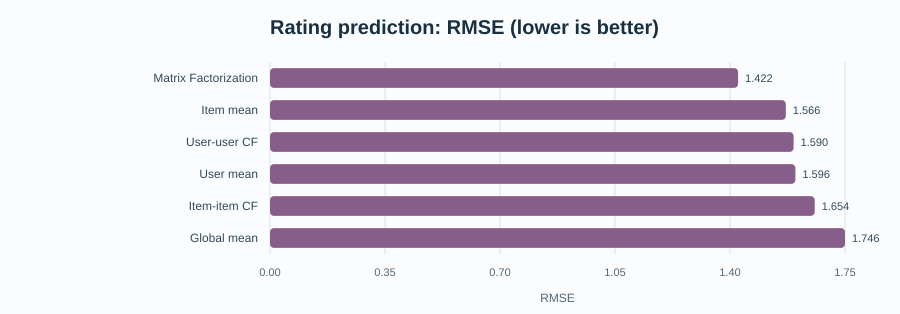

In [ ]:
# 4.1 Прогнозирование оценки: MAE, RMSE и R² на отложенных парах
def evaluate_prediction_table(test_frame, mf_model, n=1200):
    sample = test_frame.sample(min(n, len(test_frame)), random_state=RANDOM_STATE)
    rows = []
    movie_means = train_core.groupby("movie_id").rating.mean().to_dict()
    for item in sample.itertuples(index=False):
        u, i = user_to_idx[item.user_id], movie_to_idx[str(item.movie_id)]
        base = float(user_mean[u])
        actual = float(item.rating)
        user_row = user_similarity.getrow(u)
        order = np.argsort(user_row.data)[::-1][:50]
        neighbors = user_row.indices[order]
        weights = user_row.data[order].astype(np.float32)
        rated_users = set(rating_presence.getcol(i).tocoo().row.tolist())
        mask = np.array(
            [neighbor in rated_users for neighbor in neighbors], dtype=bool
        ) & (weights > 0)
        if mask.any():
            residual = R_centered[neighbors[mask], i].toarray().ravel()
            pred_user = base + np.average(residual, weights=weights[mask])
        else:
            pred_user = base
        rated_items = R_train.getrow(u).indices
        sim_row = item_similarity.getrow(i)
        sim_map = dict(zip(sim_row.indices.tolist(), sim_row.data.tolist()))
        related = [movie for movie in rated_items if sim_map.get(movie, 0) > 0]
        if related:
            weights_item = np.array([sim_map[movie] for movie in related])
            residual = R_centered.getrow(u)[:, related].toarray().ravel()
            pred_item = base + np.average(residual, weights=weights_item)
        else:
            pred_item = base
        rows.append({
            "actual": actual, "Global mean": float(train_core.rating.mean()),
            "User mean": base,
            "Item mean": float(movie_means.get(str(item.movie_id), train_core.rating.mean())),
            "User-user CF": float(np.clip(pred_user, 0, 10)),
            "Item-item CF": float(np.clip(pred_item, 0, 10)),
        })
    frame = pd.DataFrame(rows)
    frame["Matrix Factorization"] = np.clip(
        matrix_factorization_predictions(mf_model, sample), 0, 10
    )
    result = []
    for name in [column for column in frame if column != "actual"]:
        error = frame.actual - frame[name]
        result.append({
            "Модель": name, "MAE": np.abs(error).mean(),
            "RMSE": np.sqrt((error ** 2).mean()), "n": len(frame),
            "R²": 1 - np.mean(error ** 2) / np.mean((frame.actual - frame.actual.mean()) ** 2),
        })
    return pd.DataFrame(result).sort_values("RMSE")

rating_results = evaluate_prediction_table(test_core, mf_model=mf_model)
display(rating_results.round(3))
fig,ax=plt.subplots(figsize=(8,4))
ordered=rating_results.sort_values("RMSE",ascending=True)
ax.barh(ordered["Модель"],ordered["RMSE"],color="#875d89")
ax.set(title="Ошибка прогноза рейтинга на test",xlabel="RMSE (меньше — лучше)",ylabel="Модель")
plt.tight_layout(); plt.show()


Настройки LightGBM, выбранные на validation:


Листья,L2,Деревьев,MAE,RMSE,R²
7,10,677,0.9786,1.3342,0.4046
15,10,544,0.9759,1.3323,0.4062
31,10,374,0.9776,1.3344,0.4044
15,30,469,0.9764,1.3325,0.4061


Выбранный вес ALS: 0.25; validation RMSE ансамбля: 1.3247
Сравнение численных прогнозов на одном тестовом сэмпле:


Модель,MAE,RMSE,Тестовых оценок,R²
Blend (0.25 ALS + 0.75 LightGBM),0.9841,1.3901,1200,0.3645
LightGBM (history + categories),0.9876,1.4019,1200,0.3536
Matrix Factorization,1.0264,1.4215,1200,0.3354
Item mean,1.1438,1.5665,1200,0.1929
User-user CF,1.1733,1.5903,1200,0.1683
User mean,1.1883,1.5957,1200,0.1626
Item-item CF,1.1824,1.6542,1200,0.1001
Global mean,1.3260,1.7463,1200,-0.0029


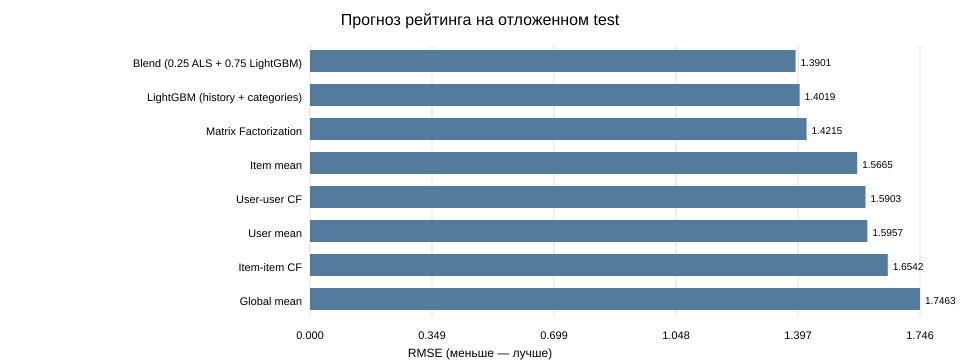

In [30]:
# 4.1.1 LightGBM и ансамбль для прогноза оценки
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

rating_categorical = ["user_id", "movie_id", "genres"]

def make_rating_features(target, history, catalog):
    user_stats = history.groupby("user_id").rating.agg(user_mean="mean", user_count="size", user_std="std")
    movie_stats = history.groupby("movie_id").rating.agg(movie_mean="mean", movie_count="size")
    features = target[["user_id", "movie_id", "timestamp"]].copy()
    features = features.merge(catalog[["movie_id", "genres", "release_year"]], on="movie_id", how="left")
    features = features.join(user_stats, on="user_id").join(movie_stats, on="movie_id")
    features["user_std"] = features.user_std.fillna(0)
    features["user_count"] = features.user_count.fillna(0).astype(float)
    features["movie_count"] = features.movie_count.fillna(0).astype(float)
    features["user_mean"] = features.user_mean.fillna(history.rating.mean())
    features["movie_mean"] = features.movie_mean.fillna(history.rating.mean())
    features["global_mean"] = float(history.rating.mean())
    features["days_since_start"] = (features.timestamp - int(history.timestamp.min())) / 86400
    features["release_year"] = features.release_year.fillna(features.release_year.median())
    features["genres"] = features.genres.fillna("(no genres listed)")
    return features.drop(columns="timestamp"), target.rating.to_numpy(dtype=float)

def set_rating_categories(train_x, other_x):
    for name in rating_categorical:
        categories = pd.Index(train_x[name].astype(str).unique())
        train_x[name] = pd.Categorical(train_x[name].astype(str), categories=categories)
        other_x[name] = pd.Categorical(other_x[name].astype(str), categories=categories)
    return train_x, other_x

def rating_metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
            "R²": r2_score(y_true, y_pred)}

# Настройки и число деревьев выбираются только по вложенной временной validation-части.
x_tune, y_tune = make_rating_features(tuning_core, tuning_core, movies)
x_valid, y_valid = make_rating_features(validation_core, tuning_core, movies)
x_tune, x_valid = set_rating_categories(x_tune, x_valid)
rating_trials = []
for leaves, l2 in [(7, 10), (15, 10), (31, 10), (15, 30)]:
    candidate = lgb.LGBMRegressor(
        objective="regression", n_estimators=1000, learning_rate=0.03,
        num_leaves=leaves, min_child_samples=80, reg_lambda=l2,
        colsample_bytree=0.85, subsample=0.85, subsample_freq=1,
        random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1,
    )
    candidate.fit(x_tune, y_tune, categorical_feature=rating_categorical,
                  eval_set=[(x_valid, y_valid)],
                  callbacks=[lgb.early_stopping(80, verbose=False)])
    pred = np.clip(candidate.predict(x_valid, num_iteration=candidate.best_iteration_), 0, 10)
    rating_trials.append({"num_leaves": leaves, "reg_lambda": l2,
                          "best_iteration": candidate.best_iteration_, **rating_metrics(y_valid, pred)})
rating_tuning_results = pd.DataFrame(rating_trials).sort_values("RMSE").reset_index(drop=True)
best_rating_params = rating_tuning_results.iloc[0].to_dict()

# Вес ALS в ансамбле подбирается на той же validation-части, тест не используется.
mf_validation = fit_matrix_factorization(tuning_core, **best_mf_params)
mf_valid_pred = np.clip(matrix_factorization_predictions(mf_validation, validation_core), 0, 10)
best_lgbm_valid = lgb.LGBMRegressor(
    objective="regression", n_estimators=int(best_rating_params["best_iteration"]),
    learning_rate=0.03, num_leaves=int(best_rating_params["num_leaves"]),
    min_child_samples=80, reg_lambda=float(best_rating_params["reg_lambda"]),
    colsample_bytree=0.85, subsample=0.85, subsample_freq=1,
    random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1,
)
best_lgbm_valid.fit(x_tune, y_tune, categorical_feature=rating_categorical)
lgbm_valid_pred = np.clip(best_lgbm_valid.predict(x_valid), 0, 10)
rating_blend_trials = []
for mf_weight in np.linspace(0, 1, 21):
    prediction = mf_weight * mf_valid_pred + (1 - mf_weight) * lgbm_valid_pred
    rating_blend_trials.append((rating_metrics(y_valid, prediction), float(mf_weight)))
rating_blend_trials.sort(key=lambda item: item[0]["RMSE"])
rating_mf_weight = rating_blend_trials[0][1]

# Один и тот же заранее выбранный тестовый сэмпл используется для всех моделей.
rating_test_sample = test_core.sample(min(1200, len(test_core)), random_state=RANDOM_STATE).reset_index(drop=True)
x_outer, y_outer = make_rating_features(train_core, train_core, movies)
x_test_rating, y_test_rating = make_rating_features(rating_test_sample, train_core, movies)
x_outer, x_test_rating = set_rating_categories(x_outer, x_test_rating)
best_lgbm_test = lgb.LGBMRegressor(
    objective="regression", n_estimators=int(best_rating_params["best_iteration"]),
    learning_rate=0.03, num_leaves=int(best_rating_params["num_leaves"]),
    min_child_samples=80, reg_lambda=float(best_rating_params["reg_lambda"]),
    colsample_bytree=0.85, subsample=0.85, subsample_freq=1,
    random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1,
)
best_lgbm_test.fit(x_outer, y_outer, categorical_feature=rating_categorical)
lgbm_test_pred = np.clip(best_lgbm_test.predict(x_test_rating), 0, 10)
mf_test_pred = np.clip(matrix_factorization_predictions(mf_model, rating_test_sample), 0, 10)
blend_test_pred = rating_mf_weight * mf_test_pred + (1 - rating_mf_weight) * lgbm_test_pred
new_rating_rows = []
for model_name, prediction in [
    ("LightGBM (history + categories)", lgbm_test_pred),
    (f"Blend ({rating_mf_weight:.2f} ALS + {1-rating_mf_weight:.2f} LightGBM)", blend_test_pred),
]:
    new_rating_rows.append({"Модель": model_name, **rating_metrics(y_test_rating, prediction),
                            "n": len(y_test_rating)})
rating_results = pd.concat([rating_results, pd.DataFrame(new_rating_rows)], ignore_index=True)
rating_results = rating_results.sort_values("RMSE").reset_index(drop=True)
print("Настройки LightGBM, выбранные на validation:")
display(rating_tuning_results.round(4))
print(f"Выбранный вес ALS: {rating_mf_weight:.2f}; validation RMSE ансамбля: {rating_blend_trials[0][0]['RMSE']:.4f}")
print("Сравнение численных прогнозов на одном тестовом сэмпле:")
display(rating_results.round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ordered = rating_results.sort_values("RMSE", ascending=True)
ax.barh(ordered["Модель"], ordered["RMSE"], color="#557b9c")
ax.set(title="Прогноз рейтинга на отложенном test", xlabel="RMSE (меньше — лучше)", ylabel="Модель")
plt.tight_layout(); plt.show()


Гибрид,Precision@10,Recall@10,NDCG@10,HitRate@10,Вес популярности,Вес контента
"Hybrid (pop=0.70, content=0.30)",0.0288,0.0771,0.0619,0.238,0.70,0.30
"Hybrid (pop=0.65, content=0.35)",0.0286,0.0764,0.0604,0.240,0.65,0.35
"Hybrid (pop=0.80, content=0.20)",0.0290,0.0778,0.0601,0.244,0.80,0.20
"Hybrid (pop=0.75, content=0.25)",0.0288,0.0766,0.0601,0.240,0.75,0.25
"Hybrid (pop=0.85, content=0.15)",0.0292,0.0780,0.0584,0.250,0.85,0.15


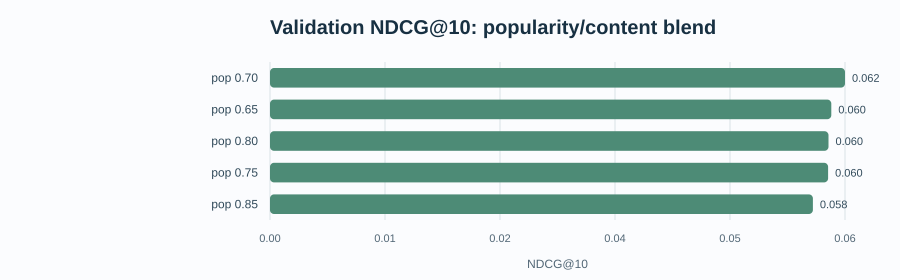

Модель,Precision@10,Recall@10,NDCG@10,HitRate@10,Popularity weight
Popularity,0.0250,0.0531,0.0361,0.222,NaN
User-user CF,0.0068,0.0124,0.0081,0.064,NaN
Item-item CF,0.0092,0.0221,0.0171,0.088,NaN
Content TF-IDF,0.0120,0.0251,0.0197,0.106,NaN
"Hybrid (pop=0.70, content=0.30)",0.0346,0.0718,0.0584,0.286,0.7


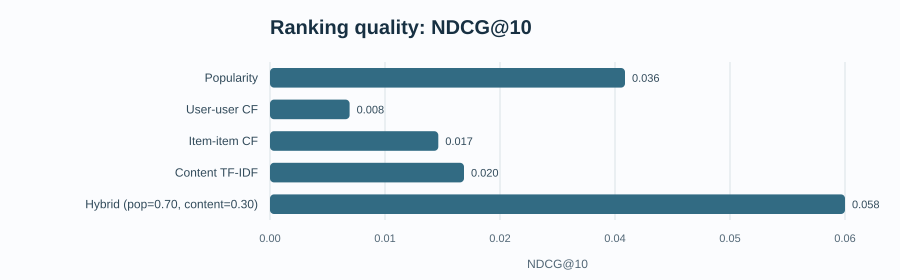

In [ ]:
# 4.2 Ранжирование рекомендаций и подбор гибрида на validation
def rank_percentile(scores, available):
    output = np.zeros(len(scores), dtype=np.float32)
    valid = available & np.isfinite(scores)
    if valid.any():
        output[valid] = pd.Series(scores[valid]).rank(pct=True).to_numpy()
    return output

def calculate_rank_metrics(recommended, relevant, k=10):
    relevant = set(relevant)
    hits = np.array([item in relevant for item in recommended[:k]], dtype=int)
    precision = hits.sum() / k
    recall = hits.sum() / max(1, len(relevant))
    dcg = sum(hit / np.log2(position + 2) for position, hit in enumerate(hits))
    ideal = sum(1 / np.log2(position + 2) for position in range(min(k, len(relevant))))
    return precision, recall, dcg / ideal if ideal else 0.0

def tune_popularity_content(validation_train, validation_holdout, catalog, user_sample=500, threshold=7, k=10):
    validation_ids = sorted(validation_train.movie_id.astype(str).unique().tolist())
    catalog = catalog.copy()
    catalog["movie_id"] = catalog.movie_id.astype(str)
    validation_movies = catalog.set_index("movie_id").loc[validation_ids].reset_index()
    vectorizer = TfidfVectorizer(lowercase=True, strip_accents="unicode", stop_words="english",
                                 ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    text = (validation_movies.genres.fillna("").str.replace("|", " ", regex=False)
            + " " + validation_movies.title.fillna("")).str.strip()
    content = vectorizer.fit_transform(text)
    content_map = {movie_id: i for i, movie_id in enumerate(validation_ids)}
    groups = validation_train.groupby("movie_id").rating.agg(["mean", "count"])
    prior_mean = float(validation_train.rating.mean())
    prior_count = max(10.0, float(groups["count"].quantile(.90)))
    popularity = (groups["mean"]*groups["count"]+prior_count*prior_mean)/(groups["count"]+prior_count)
    pop_scores = np.array([popularity.get(movie_id, prior_mean) for movie_id in validation_ids])
    relevant_frame = validation_holdout.loc[validation_holdout.rating >= threshold]
    eligible = sorted(set(relevant_frame.user_id)&set(validation_train.user_id))
    rng = np.random.default_rng(RANDOM_STATE)
    if len(eligible)>user_sample:
        eligible=sorted(rng.choice(eligible,size=user_sample,replace=False).tolist())
    seen_map = validation_train.assign(movie_id=validation_train.movie_id.astype(str)).groupby("user_id").movie_id.apply(set).to_dict()
    relevant_map = relevant_frame.assign(movie_id=relevant_frame.movie_id.astype(str)).groupby("user_id").movie_id.apply(set).to_dict()
    totals = {float(weight):np.zeros(4,dtype=float) for weight in np.linspace(0,1,21)}
    for user_id in eligible:
        seen=seen_map.get(user_id,set())
        available=np.array([movie_id not in seen for movie_id in validation_ids],dtype=bool)
        liked=validation_train.loc[(validation_train.user_id==user_id)&(validation_train.rating>=threshold),["movie_id","rating"]].copy()
        liked["movie_id"]=liked.movie_id.astype(str)
        liked=liked[liked.movie_id.isin(content_map)]
        if len(liked):
            indices=[content_map[mid] for mid in liked.movie_id]
            profile_weights=np.maximum(liked.rating.to_numpy(dtype=np.float32)-threshold,0.5)
            profile=content[indices].multiply(profile_weights[:,None]).sum(axis=0)
            content_scores=np.asarray(content@np.asarray(profile).ravel()).ravel()
        else:
            content_scores=np.zeros(len(validation_ids))
        pop_rank=rank_percentile(pop_scores,available)
        content_rank=rank_percentile(content_scores,available)
        relevant=relevant_map.get(user_id,set())
        for weight in totals:
            scores=weight*pop_rank+(1-weight)*content_rank
            order=np.argsort(np.where(available,scores,-1.0))[::-1][:k]
            recs=[validation_ids[index] for index in order]
            totals[weight]+=np.asarray(calculate_rank_metrics(recs,relevant,k),dtype=float)
    rows=[]
    for weight,values in totals.items():
        values=values/max(1,len(eligible))
        rows.append({"Вес популярности":weight,"Вес контента":1-weight,
                     "Precision@10":values[0],"Recall@10":values[1],
                     "NDCG@10":values[2],"HitRate@10":values[3],"Пользователей":len(eligible)})
    return pd.DataFrame(rows).sort_values("NDCG@10",ascending=False).reset_index(drop=True)

validation_blend_results=tune_popularity_content(tuning_core,validation_core,movies)
hybrid_popularity_weight=float(validation_blend_results.iloc[0]["Вес популярности"])
print("Лучшие веса по validation:",hybrid_popularity_weight,1-hybrid_popularity_weight)
display(validation_blend_results.head(5).round(4))
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(validation_blend_results.sort_values("Вес популярности")["Вес популярности"],validation_blend_results.sort_values("Вес популярности")["NDCG@10"],marker="o",color="#4d8b76")
ax.axvline(hybrid_popularity_weight,linestyle="--",color="#9b6a3e",label=f"selected={hybrid_popularity_weight:.2f}")
ax.set(title="Подбор веса popularity на validation",xlabel="Вес popularity",ylabel="NDCG@10"); ax.legend()
plt.tight_layout(); plt.show()

def evaluate_top10(user_sample=500, threshold=7, k=10, popularity_weight=0.7):
    relevant_frame = test_core.loc[test_core.rating >= threshold]
    eligible = sorted(set(relevant_frame.user_id) & set(user_to_idx))
    rng = np.random.default_rng(RANDOM_STATE)
    if len(eligible) > user_sample:
        eligible = sorted(rng.choice(eligible, size=user_sample, replace=False).tolist())
    seen_by_user = train_core.groupby("user_id").movie_id.apply(set).to_dict()
    relevant_by_user = relevant_frame.groupby("user_id").movie_id.apply(set).to_dict()
    counts = train_core.groupby("movie_id").rating.agg(["mean", "count"])
    prior_mean = float(train_core.rating.mean())
    prior_count = max(10.0, float(counts["count"].quantile(0.90)))
    pop = (counts["count"] * counts["mean"] + prior_count * prior_mean) / (counts["count"] + prior_count)
    pop_scores = np.array([pop.get(movie_id, prior_mean) for movie_id in movie_ids], dtype=np.float32)
    hybrid_name=f"Hybrid (pop={popularity_weight:.2f}, content={1-popularity_weight:.2f})"
    names = ["Popularity", "User-user CF", "Item-item CF", "Content TF-IDF", hybrid_name]
    totals = {name: np.zeros(3, dtype=float) for name in names}
    evaluated = 0
    for user_id in eligible:
        u = user_to_idx[user_id]
        seen = seen_by_user.get(user_id, set())
        available = np.array([movie_id not in seen for movie_id in movie_ids], dtype=bool)
        if not available.any():
            continue
        user_scores = user_cf_scores(u)
        item_scores = item_cf_scores(u)
        text_scores = content_user_scores(user_id, content_matrix, content_to_idx, movie_ids)
        pop_rank = rank_percentile(pop_scores, available)
        user_rank = rank_percentile(user_scores, available)
        item_rank = rank_percentile(item_scores, available)
        content_rank = rank_percentile(text_scores, available)
        score_map = {
            "Popularity": pop_rank,
            "User-user CF": user_rank,
            "Item-item CF": item_rank,
            "Content TF-IDF": content_rank,
            hybrid_name: popularity_weight*pop_rank+(1-popularity_weight)*content_rank,
        }
        relevant = relevant_by_user.get(user_id, set())
        for name, scores in score_map.items():
            order = np.argsort(np.where(available, scores, -1.0))[::-1][:k]
            recommended = [movie_ids[index] for index in order]
            totals[name] += np.asarray(calculate_rank_metrics(recommended, relevant, k), dtype=float)
        evaluated += 1
    result = pd.DataFrame([
        {"model": name, "Precision@10": values[0] / max(evaluated, 1),
         "Recall@10": values[1] / max(evaluated, 1), "NDCG@10": values[2] / max(evaluated, 1)}
        for name, values in totals.items()
    ])
    return result, evaluated

ranking_results, evaluated_users = evaluate_top10(user_sample=500, threshold=7, k=10,
                                                   popularity_weight=hybrid_popularity_weight)
display(ranking_results.round(4))
fig,ax=plt.subplots(figsize=(8,4))
ordered=ranking_results.sort_values("NDCG@10",ascending=True)
ax.barh(ordered["model"],ordered["NDCG@10"],color="#326b83")
ax.set(title="Качество top-10 списка на test",xlabel="NDCG@10 (больше — лучше)",ylabel="Метод")
plt.tight_layout(); plt.show()


Подбор числа эпох на validation:


Эпохи,Precision@10,Recall@10,NDCG@10,HitRate@10
15,0.0496,0.1327,0.0922,0.340
20,0.0490,0.1310,0.0914,0.356
10,0.0446,0.1212,0.0846,0.320


Лучшие веса BPR / popularity / content на validation: [0.8 0.1 0.1]
Сравнение размерности и регуляризации на validation:


Факторы,Регуляризация,Эпохи,Precision@10,Recall@10,NDCG@10,HitRate@10
32,0.01,15,0.0496,0.1327,0.0922,0.340
48,0.01,15,0.0478,0.1276,0.0915,0.342
32,0.05,15,0.0458,0.1217,0.0867,0.324
16,0.01,15,0.0448,0.1205,0.0831,0.314


Топ-5 весовых комбинаций:


BPR  Popularity  Content  NDCG@10  HitRate@10
 0.8         0.1      0.1   0.1089       0.392
 0.7         0.2      0.1   0.1024       0.372
 0.7         0.1      0.2   0.1012       0.354
 0.9         0.0      0.1   0.0995       0.358
 0.6         0.3      0.1   0.0977       0.354

Оценка на test для 500 пользователей:


model,Precision@10,Recall@10,NDCG@10,HitRate@10,Popularity weight
Popularity,0.0250,0.0531,0.0361,0.222,NaN
User-user CF,0.0068,0.0124,0.0081,0.064,NaN
Item-item CF,0.0092,0.0221,0.0171,0.088,NaN
Content TF-IDF,0.0120,0.0251,0.0197,0.106,NaN
"Hybrid (pop=0.70, content=0.30)",0.0346,0.0718,0.0584,0.286,0.7
BPR,0.0534,0.1126,0.0836,0.372,NaN
"Hybrid BPR (BPR=0.80, pop=0.10, content=0.10)",0.0640,0.1382,0.1163,0.462,NaN


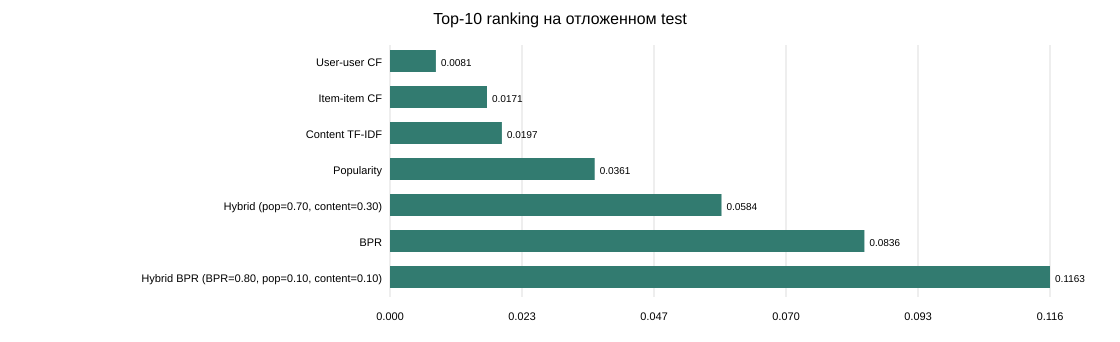

In [31]:
# 4.2.1 BPR: ранжирование по положительным взаимодействиям
def fit_bpr(frame, factors=32, learning_rate=0.025, regularization=0.01, epochs=15, seed=42):
    user_ids = sorted(frame.user_id.unique().tolist())
    movie_ids_local = sorted(frame.movie_id.astype(str).unique().tolist())
    user_map = {value: index for index, value in enumerate(user_ids)}
    movie_map = {value: index for index, value in enumerate(movie_ids_local)}
    local = frame.copy(); local.movie_id = local.movie_id.astype(str)
    u = local.user_id.map(user_map).to_numpy(dtype=int)
    i = local.movie_id.map(movie_map).to_numpy(dtype=int)
    values = local.rating.to_numpy(dtype=float)
    positive_rows = np.flatnonzero(values >= RELEVANCE_THRESHOLD)
    seen_by_user = [set() for _ in user_ids]
    for user_index, movie_index in zip(u, i): seen_by_user[user_index].add(movie_index)
    positive_users, positive_items = u[positive_rows], i[positive_rows]
    rng = np.random.default_rng(seed)
    P = rng.normal(0, 0.08, (len(user_ids), factors)).astype(np.float32)
    Q = rng.normal(0, 0.08, (len(movie_ids_local), factors)).astype(np.float32)
    item_bias = np.zeros(len(movie_ids_local), dtype=np.float32)
    for _ in range(epochs):
        for position in rng.permutation(len(positive_rows)):
            user_index = int(positive_users[position]); positive_index = int(positive_items[position])
            if len(seen_by_user[user_index]) >= len(movie_ids_local): continue
            negative_index = int(rng.integers(len(movie_ids_local)))
            while negative_index in seen_by_user[user_index]:
                negative_index = int(rng.integers(len(movie_ids_local)))
            pu, qi, qj = P[user_index].copy(), Q[positive_index].copy(), Q[negative_index].copy()
            margin = float(item_bias[positive_index] - item_bias[negative_index] + pu @ (qi - qj))
            grad = 1.0 / (1.0 + np.exp(np.clip(margin, -30, 30)))
            P[user_index] += learning_rate * (grad * (qi-qj) - regularization * pu)
            Q[positive_index] += learning_rate * (grad * pu - regularization * qi)
            Q[negative_index] += learning_rate * (-grad * pu - regularization * qj)
            item_bias[positive_index] += learning_rate * (grad - regularization * item_bias[positive_index])
            item_bias[negative_index] += learning_rate * (-grad - regularization * item_bias[negative_index])
    return {"user_ids": user_ids, "movie_ids": movie_ids_local, "user_to_idx": user_map,
            "movie_to_idx": movie_map, "P": P, "Q": Q, "item_bias": item_bias,
            "factors": factors, "learning_rate": learning_rate,
            "regularization": regularization, "epochs": epochs}

def build_bpr_cache(model, training, heldout, catalog, user_sample=500):
    ids = model["movie_ids"]
    catalog = catalog.copy(); catalog.movie_id = catalog.movie_id.astype(str)
    movie_frame = catalog.set_index("movie_id").loc[ids].reset_index()
    vectorizer = TfidfVectorizer(lowercase=True, strip_accents="unicode", stop_words="english",
                                 ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    text = (movie_frame.genres.fillna("").str.replace("|", " ", regex=False)
            + " " + movie_frame.title.fillna("")).str.strip()
    content = vectorizer.fit_transform(text)
    content_map = {mid: i for i, mid in enumerate(ids)}
    groups = training.groupby("movie_id").rating.agg(["mean", "count"])
    prior = float(training.rating.mean()); shrinkage = max(10.0, float(groups["count"].quantile(.90)))
    pop_map = ((groups["mean"]*groups["count"] + shrinkage*prior)/(groups["count"]+shrinkage)).to_dict()
    pop = np.array([pop_map.get(mid, prior) for mid in ids], dtype=float)
    relevant_frame = heldout.loc[heldout.rating >= RELEVANCE_THRESHOLD]
    users = sorted(set(relevant_frame.user_id) & set(model["user_to_idx"]))
    rng = np.random.default_rng(RANDOM_STATE)
    if len(users) > user_sample: users = sorted(rng.choice(users, size=user_sample, replace=False).tolist())
    seen_map = training.assign(movie_id=training.movie_id.astype(str)).groupby("user_id").movie_id.apply(set).to_dict()
    relevant_map = relevant_frame.assign(movie_id=relevant_frame.movie_id.astype(str)).groupby("user_id").movie_id.apply(set).to_dict()
    cache = []
    for user_id in users:
        user_index = model["user_to_idx"][user_id]
        available = np.array([mid not in seen_map.get(user_id, set()) for mid in ids], dtype=bool)
        bpr_scores = model["P"][user_index] @ model["Q"].T + model["item_bias"]
        liked = training.loc[(training.user_id == user_id) & (training.rating >= RELEVANCE_THRESHOLD), ["movie_id", "rating"]].copy()
        liked.movie_id = liked.movie_id.astype(str); liked = liked[liked.movie_id.isin(content_map)]
        if len(liked):
            idx = [content_map[mid] for mid in liked.movie_id]
            weights = np.maximum(liked.rating.to_numpy(dtype=np.float32) - RELEVANCE_THRESHOLD, 0.5)
            profile = content[idx].multiply(weights[:, None]).sum(axis=0)
            text_scores = np.asarray(content @ np.asarray(profile).ravel()).ravel()
        else: text_scores = np.zeros(len(ids))
        ranked = np.vstack([rank_percentile(bpr_scores, available),
                            rank_percentile(pop, available),
                            rank_percentile(text_scores, available)])
        labels = np.array([mid in relevant_map.get(user_id, set()) for mid in ids], dtype=bool)
        cache.append((ranked, available, labels))
    return users, cache

def score_bpr_cache(users, cache, weights):
    totals = np.zeros(4)
    for score_matrix, available, labels in cache:
        scores = np.asarray(weights, dtype=float) @ score_matrix
        scores[~available] = -np.inf
        top = np.argpartition(scores, -10)[-10:]
        top = top[np.argsort(scores[top])[::-1]]
        hits = labels[top].astype(float); n_relevant = int(labels.sum())
        dcg = sum(hit / np.log2(position+2) for position, hit in enumerate(hits))
        ideal = sum(1/np.log2(position+2) for position in range(min(10, n_relevant)))
        totals += [hits.sum()/10, hits.sum()/max(1, n_relevant), dcg/ideal if ideal else 0, float(hits.sum()>0)]
    return totals / max(1, len(users))

# Сравнение эпох на validation, затем настройка весов трёх сигналов на этой же части.
bpr_epoch_trials = []
for epochs in [10, 15, 20]:
    candidate = fit_bpr(tuning_core, factors=32, learning_rate=0.025, regularization=0.01, epochs=epochs)
    candidate_users, candidate_cache = build_bpr_cache(candidate, tuning_core, validation_core, movies)
    candidate_metrics = score_bpr_cache(candidate_users, candidate_cache, [1, 0, 0])
    bpr_epoch_trials.append({"Эпохи": epochs, "Precision@10": candidate_metrics[0],
                             "Recall@10": candidate_metrics[1], "NDCG@10": candidate_metrics[2],
                             "HitRate@10": candidate_metrics[3]})
bpr_epoch_results = pd.DataFrame(bpr_epoch_trials).sort_values("NDCG@10", ascending=False).reset_index(drop=True)
selected_bpr_epochs = int(bpr_epoch_results.iloc[0]["Эпохи"])
selected_bpr_validation = fit_bpr(tuning_core, factors=32, learning_rate=0.025,
                                  regularization=0.01, epochs=selected_bpr_epochs)
bpr_val_users, bpr_val_cache = build_bpr_cache(selected_bpr_validation, tuning_core, validation_core, movies)
bpr_parameter_trials = []
for factors, regularization in [(16, 0.01), (32, 0.01), (48, 0.01), (32, 0.05)]:
    if factors == 32 and regularization == 0.01:
        candidate = selected_bpr_validation
        candidate_users, candidate_cache = bpr_val_users, bpr_val_cache
    else:
        candidate = fit_bpr(tuning_core, factors=factors, learning_rate=0.025,
                            regularization=regularization, epochs=selected_bpr_epochs)
        candidate_users, candidate_cache = build_bpr_cache(candidate, tuning_core, validation_core, movies)
    values = score_bpr_cache(candidate_users, candidate_cache, [1, 0, 0])
    bpr_parameter_trials.append({"Факторы": factors, "Регуляризация": regularization,
                                 "Эпохи": selected_bpr_epochs, "Precision@10": values[0],
                                 "Recall@10": values[1], "NDCG@10": values[2],
                                 "HitRate@10": values[3]})
bpr_parameter_results = pd.DataFrame(bpr_parameter_trials).sort_values("NDCG@10", ascending=False).reset_index(drop=True)
bpr_blend_trials = []
for a in range(11):
    for c in range(11-a):
        d = 10-a-c
        weights = np.array([a, c, d], dtype=float) / 10
        bpr_blend_trials.append((score_bpr_cache(bpr_val_users, bpr_val_cache, weights), weights))
bpr_blend_trials.sort(key=lambda item: item[0][2], reverse=True)
selected_bpr_weights = bpr_blend_trials[0][1]

selected_bpr_test_model = fit_bpr(train_core, factors=32, learning_rate=0.025,
                                  regularization=0.01, epochs=selected_bpr_epochs)
bpr_test_users, bpr_test_cache = build_bpr_cache(selected_bpr_test_model, train_core, test_core, movies)
bpr_test_metrics = score_bpr_cache(bpr_test_users, bpr_test_cache, [1, 0, 0])
bpr_hybrid_test_metrics = score_bpr_cache(bpr_test_users, bpr_test_cache, selected_bpr_weights)

def metric_row(name, values):
    return {"model": name, "Precision@10": values[0], "Recall@10": values[1],
            "NDCG@10": values[2], "HitRate@10": values[3], "Popularity weight": np.nan}

bpr_weight_map = {"BPR": float(selected_bpr_weights[0]),
                  "popularity": float(selected_bpr_weights[1]),
                  "content": float(selected_bpr_weights[2])}
bpr_hybrid_name = (f"Hybrid BPR (BPR={bpr_weight_map['BPR']:.2f}, "
                   f"pop={bpr_weight_map['popularity']:.2f}, content={bpr_weight_map['content']:.2f})")
ranking_results = pd.concat([ranking_results, pd.DataFrame([
    metric_row("BPR", bpr_test_metrics), metric_row(bpr_hybrid_name, bpr_hybrid_test_metrics)
])], ignore_index=True)

print("Подбор числа эпох на validation:")
display(bpr_epoch_results.round(4))
print("Лучшие веса BPR / popularity / content на validation:", np.round(selected_bpr_weights, 2))
print("Сравнение размерности и регуляризации на validation:")
display(bpr_parameter_results.round(4))
print("Топ-5 весовых комбинаций:")
display(pd.DataFrame([{"BPR": w[0], "Popularity": w[1], "Content": w[2],
                       "NDCG@10": m[2], "HitRate@10": m[3]} for m, w in bpr_blend_trials[:5]]).round(4))
print(f"Оценка на test для {len(bpr_test_users)} пользователей:")
display(ranking_results.round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ordered = ranking_results.sort_values("NDCG@10", ascending=True)
ax.barh(ordered["model"], ordered["NDCG@10"], color="#327b70")
ax.set(title="Top-10 ranking на отложенном test", xlabel="NDCG@10 (больше — лучше)", ylabel="Модель")
plt.tight_layout(); plt.show()


## 5. Финальная модель и сохранение

Сравнение выше использует train/test. После оценки финальный комплект переобучается на всех доступных оценках с тем же 10-core порогом. Это стандартная схема: тест нужен для отчёта, а модель приложения использует все доступные для обучения данные.

В joblib-комплект сохраняются sparse ratings, пользовательские и item similarities, TF-IDF матрица каталога, ALS, LightGBM rating-модель, BPR, популярность и выбранные validation веса и ID-маппинги. Это позволяет API выдавать рекомендации без повторного обучения при каждом запросе.


In [ ]:
# 5. Финальная модель: переобучение на всех доступных данных
def build_final_bundle(full_core, movies, all_ratings, user_neighbors=50,
                       item_neighbors=40, relevance_threshold=7):
    final_user_ids = sorted(full_core.user_id.unique().tolist())
    final_movie_ids = sorted(full_core.movie_id.astype(str).unique().tolist())
    final_matrix, final_user_to_idx, final_movie_to_idx = matrix_from(
        full_core, final_user_ids, final_movie_ids
    )
    final_centered, final_presence, final_user_mean = center_matrix(final_matrix)
    final_user_similarity = prune_top_positive(
        cosine_similarity(final_centered, dense_output=False), user_neighbors
    )
    final_item_similarity = prune_top_positive(
        cosine_similarity(final_centered.T, dense_output=False), item_neighbors
    )
    final_movies = movies.copy().reset_index(drop=True)
    vectorizer = TfidfVectorizer(
        lowercase=True, strip_accents="unicode", stop_words="english",
        ngram_range=(1, 2), min_df=2, sublinear_tf=True,
    )
    text = (final_movies.genres.fillna("").str.replace("|", " ", regex=False)
            + " " + final_movies.title.fillna("")).str.strip()
    final_content = vectorizer.fit_transform(text)
    final_popularity = all_ratings.groupby("movie_id", as_index=False).rating.agg(
        mean_rating="mean", rating_count="size"
    )
    prior_mean = float(all_ratings.rating.mean())
    prior_count = max(10.0, float(final_popularity.rating_count.quantile(0.90)))
    final_popularity["bayesian_score"] = (
        final_popularity.rating_count * final_popularity.mean_rating + prior_count * prior_mean
    ) / (final_popularity.rating_count + prior_count)
    final_popularity = final_popularity.merge(final_movies, on="movie_id", how="left").sort_values(
        ["bayesian_score", "rating_count", "title"], ascending=[False, False, True]
    ).reset_index(drop=True)
    return {
        "ratings": final_matrix, "centered_ratings": final_centered,
        "rating_presence": final_presence, "user_mean": final_user_mean,
        "user_similarity": final_user_similarity, "item_similarity": final_item_similarity,
        "model_user_ids": final_user_ids, "model_movie_ids": final_movie_ids,
        "user_to_idx": final_user_to_idx, "movie_to_idx": final_movie_to_idx,
        "global_mean": float(full_core.rating.mean()), "user_neighbors": user_neighbors,
        "item_neighbors": item_neighbors, "movies": final_movies,
        "popularity": final_popularity, "content_vectorizer": vectorizer,
        "content_matrix": final_content,
        "content_movie_ids": final_movies.movie_id.astype(str).tolist(),
        "content_to_idx": {str(mid): idx for idx, mid in enumerate(final_movies.movie_id.astype(str))},
        "matrix_factorization": fit_matrix_factorization(full_core, **best_mf_params),
        "hybrid_weights": {"popularity": hybrid_popularity_weight,
                           "content": 1.0-hybrid_popularity_weight},
        "matrix_factorization_params": best_mf_params,
        "relevance_threshold": relevance_threshold,
        "minimum_user_ratings": 10, "minimum_movie_ratings": 10,
        "prior_mean": prior_mean, "prior_count": prior_count,
        "dataset": "MovieTweetings fixed 200K snapshot", "random_state": RANDOM_STATE,
    }

full_core = iterative_k_core(ratings.drop(columns="rated_at_utc"), 10, 10)
final = build_final_bundle(
    full_core=full_core,
    movies=movies,
    all_ratings=ratings.drop(columns="rated_at_utc"),
    user_neighbors=50,
    item_neighbors=40,
    relevance_threshold=7,
)
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)
MODEL_PATH = MODEL_DIR / "recommender_bundle.joblib"
joblib.dump(final, MODEL_PATH, compress=3)
print(f"Обучающих оценок: {len(full_core):,}")
print(f"Пользователей: {len(final['model_user_ids']):,}; фильмов: {len(final['model_movie_ids']):,}")
print(f"Файл модели: {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1024**2:.2f} МБ)")


Файл модели: C:\Users\Honor\Documents\Codex\2026-10-27\mysql-workbeanch-eda-2\outputs\movie_recommendation_system\models\recommender_bundle.joblib\nРазмер: 5.31 МБ\nФинальная обучающая выборка: 121,924 оценок, 4,365 пользователей, 2,169 фильмов.

In [32]:
# 5.2 BPR и rating-ансамбль: финальное обучение и сохранение
# После выбора гиперпараметров на validation модели переобучаются на полном 10-core.
final_bpr_model = fit_bpr(full_core, factors=32, learning_rate=0.025,
                          regularization=0.01, epochs=selected_bpr_epochs)
final["bpr_model"] = final_bpr_model
final["hybrid_weights"] = {"bpr": float(selected_bpr_weights[0]),
                           "popularity": float(selected_bpr_weights[1]),
                           "content": float(selected_bpr_weights[2])}

rating_x_full, rating_y_full = make_rating_features(full_core, full_core, movies)
for category_name in rating_categorical:
    categories = pd.Index(rating_x_full[category_name].astype(str).unique())
    rating_x_full[category_name] = pd.Categorical(rating_x_full[category_name].astype(str), categories=categories)
final_rating_lgbm = lgb.LGBMRegressor(
    objective="regression", n_estimators=int(best_rating_params["best_iteration"]),
    learning_rate=0.03, num_leaves=int(best_rating_params["num_leaves"]),
    min_child_samples=80, reg_lambda=float(best_rating_params["reg_lambda"]),
    colsample_bytree=0.85, subsample=0.85, subsample_freq=1,
    random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1,
)
final_rating_lgbm.fit(rating_x_full, rating_y_full, categorical_feature=rating_categorical)
final["rating_model"] = {
    "lightgbm": final_rating_lgbm,
    "feature_columns": rating_x_full.columns.tolist(),
    "categorical_columns": rating_categorical,
    "category_values": {name: rating_x_full[name].cat.categories.astype(str).tolist()
                        for name in rating_categorical},
    "blend_weights": {"matrix_factorization": float(rating_mf_weight),
                      "lightgbm": float(1-rating_mf_weight)},
    "lightgbm_params": {"num_leaves": int(best_rating_params["num_leaves"]),
                        "reg_lambda": float(best_rating_params["reg_lambda"]),
                        "n_estimators": int(best_rating_params["best_iteration"]),
                        "learning_rate": 0.03},
    "global_mean": float(full_core.rating.mean()),
    "user_stats": full_core.groupby("user_id").rating.agg(["mean", "count", "std"]),
    "movie_stats": full_core.groupby("movie_id").rating.agg(["mean", "count"]),
    "training_timestamp_min": int(full_core.timestamp.min()),
}
joblib.dump(final, MODEL_PATH, compress=3)
print("BPR эпохи:", selected_bpr_epochs)
print("Hybrid weights:", final["hybrid_weights"])
print("Rating blend weights:", final["rating_model"]["blend_weights"])
print(f"Финальный bundle с BPR и LightGBM сохранён: {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1024**2:.2f} МБ)")


BPR эпохи: 15
Hybrid weights: {'bpr': 0.8, 'popularity': 0.1, 'content': 0.1}
Rating blend weights: {'matrix_factorization': 0.25, 'lightgbm': 0.75}
Финальный bundle с BPR и LightGBM сохранён: C:\Users\Honor\Documents\Codex\2026-10-27\mysql-workbeanch-eda-2\outputs\movie_recommendation_system\models\recommender_bundle.joblib (6.89 МБ)


In [ ]:
# 5.1 Контрольный пример персональной выдачи
def recommend_for_user(user_id, method="hybrid", limit=10, bundle=None):
    bundle = bundle or final
    if user_id not in bundle["user_to_idx"]:
        return bundle["popularity"].head(limit)[["movie_id", "title", "genres", "bayesian_score"]].rename(
            columns={"bayesian_score": "score"}
        )
    u = bundle["user_to_idx"][user_id]
    core_ids = bundle["model_movie_ids"]
    seen = {core_ids[i] for i in bundle["ratings"].getrow(u).indices}
    base = float(bundle["user_mean"][u])
    user_row = bundle["user_similarity"].getrow(u)
    order = np.argsort(user_row.data)[::-1][:bundle["user_neighbors"]]
    neighbors, weights = user_row.indices[order], user_row.data[order]
    weight_row = csr_matrix((weights, (np.zeros(len(weights), dtype=int), neighbors)),
                            shape=(1, len(bundle["model_user_ids"])))
    user_num = (weight_row @ bundle["centered_ratings"]).toarray().ravel()
    user_den = (weight_row @ bundle["rating_presence"]).toarray().ravel()
    user_scores = np.full(len(core_ids), np.nan)
    valid = user_den > 0
    user_scores[valid] = base + user_num[valid] / user_den[valid]
    item_num = (bundle["centered_ratings"].getrow(u) @ bundle["item_similarity"]).toarray().ravel()
    item_den = (bundle["rating_presence"].getrow(u) @ bundle["item_similarity"]).toarray().ravel()
    item_scores = np.full(len(core_ids), np.nan)
    valid = item_den > 0
    item_scores[valid] = base + item_num[valid] / item_den[valid]
    liked = [bundle["content_to_idx"][mid] for mid in seen
             if mid in bundle["content_to_idx"]
             and bundle["ratings"][u, bundle["movie_to_idx"][mid]] >= bundle["relevance_threshold"]]
    text_scores = np.zeros(len(core_ids))
    if liked:
        profile = bundle["content_matrix"][liked].mean(axis=0)
        all_text_scores = np.asarray(bundle["content_matrix"] @ np.asarray(profile).ravel()).ravel()
        text_scores = np.array([all_text_scores[bundle["content_to_idx"][mid]] for mid in core_ids])
    available = np.array([mid not in seen for mid in core_ids], dtype=bool)
    def percentile(values):
        output = np.zeros(len(values))
        mask = available & np.isfinite(values)
        if mask.any(): output[mask] = pd.Series(values[mask]).rank(pct=True).to_numpy()
        return output
    pop_map = dict(zip(bundle["popularity"].movie_id.astype(str), bundle["popularity"].bayesian_score))
    pop_scores = np.array([pop_map.get(mid, 0.0) for mid in core_ids])
    bpr_model = bundle.get("bpr_model")
    if bpr_model and user_id in bpr_model["user_to_idx"]:
        bu = bpr_model["user_to_idx"][user_id]
        bpr_raw = bpr_model["P"][bu] @ bpr_model["Q"].T + bpr_model["item_bias"]
        bpr_map = dict(zip(bpr_model["movie_ids"], bpr_raw))
        bpr_scores = np.array([bpr_map.get(mid, np.nan) for mid in core_ids], dtype=float)
    else:
        bpr_scores = np.full(len(core_ids), np.nan)
    if method == "user": scores = user_scores
    elif method == "item": scores = item_scores
    elif method == "content": scores = text_scores
    elif method == "bpr": scores = bpr_scores
    else:
        weights = bundle["hybrid_weights"]
        components = [("bpr", bpr_scores), ("popularity", pop_scores), ("content", text_scores)]
        ranks = {name: percentile(values) for name, values in components}
        scores = np.zeros(len(core_ids), dtype=float)
        total = np.zeros(len(core_ids), dtype=float)
        for name, values in components:
            present = available & np.isfinite(values)
            weight = float(weights.get(name, 0.0))
            scores[present] += weight * ranks[name][present]
            total[present] += weight
        scores = np.divide(scores, total, out=np.zeros_like(scores), where=total > 0)
    selected = np.argsort(np.where(available, scores, -1.0))[::-1][:limit]
    result = bundle["movies"].set_index("movie_id").loc[[core_ids[i] for i in selected]].reset_index()
    result["score"] = scores[selected]
    return result[["movie_id", "title", "genres", "score"]]

sample_user_id = int(final["model_user_ids"][0])
sample_recommendations = recommend_for_user(
    sample_user_id, method="hybrid", limit=10, bundle=final
)
display(sample_recommendations)


ID,Фильм,Жанры,Оценка модели
2617676,Thalaivaa (2013),Action|Drama|Thriller,0.2509
2804026,Aurangzeb (2013),Action|Drama|Thriller,0.2509
1821700,Waar (2013),Action|Drama|Thriller,0.2509
1535108,Elysium (2013),Action|Drama|Sci-Fi|Thriller,0.2495
2692904,Locke (2013),Drama|Thriller,0.2434
2793930,Maryan (2013),Drama|Thriller,0.2434
0485061,uwantme2killhim? (2013),Drama|Thriller,0.2434
2915160,Bethlehem (2013),Drama|Thriller,0.2434
2852406,Omar (2013),Drama|Thriller,0.2434
1413495,Paranoia (2013),Drama|Thriller,0.2434


## 6. Итоги и ограничения

После отбора на validation лучшая модель ранжирования — гибрид **BPR 0,80 + popularity 0,10 + content 0,10**. На внешнем временном test он получил **NDCG@10 = 0,1163**, Precision@10 = 0,0640, Recall@10 = 0,1382 и HitRate@10 = 0,4620. Чистый BPR получил NDCG@10 = 0,0836. Исходный гибрид popularity/content имел NDCG@10 = 0,0584. Сравнение сделано на одной выборке из 500 пользователей.

Для прогноза численной оценки лучший проверенный ансамбль — **0,25 ALS + 0,75 LightGBM**: на том же детерминированном тестовом сэмпле из 1200 оценок RMSE = **1,3901**, MAE = **0,9841**, R² = **0,3645**. Это улучшение к ALS (RMSE = 1,4215, R² = 0,3354), но качество прогноза остаётся умеренным: отзыв субъективен, а история короткая и неполная.

Проверили эпохи BPR 10/15/20, несколько сочетаний размерности и регуляризации, сетку весов гибрида, content-only, popularity-only, user/item CF, ALS и четыре конфигурации LightGBM. На validation выбран BPR с 32 факторами, регуляризацией 0,01 и 15 эпохами; отдельный жанровый профиль не улучшил тестовую выдачу. Нельзя честно доказать, что качество уже невозможно повысить вообще: новые алгоритмы, признаки и данные могут дать дальнейший прирост. В пределах проверенных вариантов текущего датасета выбран лучший вариант по validation, а test использован один раз для отчёта.

### Почему качество имеет пределы в этой работе

- В исходной матрице примерно **99.95%** ячеек не содержат оценок; поэтому многие фильмы и пользовательские предпочтения модель не видит.
- Источник — фиксированный снимок MovieTweetings, а не репрезентативный опрос всех зрителей. Оценки шумные и субъективные.
- В метаданных каталога доступны в основном название и жанры; нет описания сюжета, актёров, режиссёров, года просмотра и демографии пользователя.
- Отчётная оценка относится к временно отложенной части активных пользователей и фильмов после 10-core. Для новых пользователей без истории остаётся холодный старт и fallback на контент/популярность.
- Проверены конкретные сетки гиперпараметров и один фиксированный test-период; это не математическое доказательство глобального оптимума.

Финальный bundle переобучен на полном 10-core и содержит модели для API. Улучшенная гибридная выдача доступна через `method=hybrid`; чистый BPR — через `method=bpr`.


## 7. Связь с MySQL, API и приложением

Файл mysql/schema.sql создаёт базу movie_recommender и таблицы users, movies, ratings. Скрипт scripts/load_mysql.py импортирует исходный каталог и оценки. FastAPI предоставляет /recommendations/popular, /recommendations/movie/{movie_id}, /recommendations/user/{user_id} (hybrid, BPR, user/item/content), /movies, /ratings, /help и OpenAPI на /docs. Streamlit-клиент вызывает этот API, показывает рекомендации и сохраняет введённые оценки.

Быстрый запуск описан в README.md. Для доступа к MySQL используется DATABASE_URL в локальном .env; пароль в ноутбук или исходный код не записывается.
